# Unit 2: Soft Alignments and the SDTW Gradient

[Course overview](00_overview.ipynb)

<ul>
<li><a href="#learn" style="color:#E65100;"><strong>Overview and Learning Objectives</strong></a></li>
<li><a href="#single_path" style="color:black;">A Single Dominant Path</a></li>
<li><a href="#two_paths" style="color:black;">Two Dominant Paths</a></li>
<li><a href="#expected_paths" style="color:#1B5E20;">Background: Expected Alignments</a></li>
<li><a href="#exercise_costs" style="color:#006064;">Exercise 1: Designing a Cost Matrix</a></li>
<li><a href="#exercise_global" style="color:#006064;">Exercise 2: Global and Recursive SDTW</a></li>
</ul>

<a id="learn"></a>

<div style="
  background-color: #FFE0B2A0;
  border: 1px solid #FFC671A0;
  padding-top: 10px;
  padding-bottom: 10px;
  padding-left: 20px;
  padding-right: 20px;
  margin-top: 10px;
  margin-bottom: 10px;
">

<h2 style="color:#E65100; margin-top:0;">Overview and Learning Objectives</h2>

<p style="color:#E65100;">In this notebook, we interpret the SDTW gradient as a weighted combination of
    paths. We explore one or two low-cost corridors and the effect of softmin temperature.
    In exercises, we enumerate a small path set and verify the global SDTW formula against
    dynamic programming, as developed in Section 4 of the article.</p>

</div>

In [1]:
# --- Core scientific stack ---
import numpy as np
import torch
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt
from ddtw import SDTW

# --- Figure display and style ---
%config InlineBackend.figure_formats = ['svg']
plt.rcParams.update({"font.size": 8, "axes.titlesize": 9})

<a id="single_path"></a>

## A Single Dominant Path

Each entry $\mathbf{C}(n,m)$ is the cost of matching the vectors $x_n$ and $y_m$. The white path corridor contains low costs. DTW selects a minimum-cost path; SDTW replaces the minimum over path costs by a soft minimum.

For unit step weights, the gradient $\mathbf{E}=\partial\mathrm{SDTW}_\gamma/\partial \mathbf{C}$ is the soft alignment matrix. Its entries indicate how strongly each $(n,m)$-pair contributes to the overall cost. Small $\gamma$ emphasizes few cost-minimizing paths, while larger $\gamma$ also gives weight to more costly paths.

In [2]:
def generate_cost_matrix(
    N=100, M=60, n_paths=1, sigma=2.0, noise_level=0.1, seed=42
):
    """Generate a random cost matrix with Gaussian smoothing."""

    assert n_paths in [1, 2], "Only 1 or 2 paths are supported."

    np.random.seed(seed)
    C_ = np.zeros([N, M])
    x_ = np.arange(N) / N
    y_ = np.cos(x_ * np.pi / 2 + np.pi) + 1

    for x, y in zip(x_, y_):
        C_[int(y * N), int(x * M)] = 1.0
        if n_paths == 2:
            C_[int(x * N), int(y * M)] = 1.0

    C_ = 1 - gaussian_filter(C_, sigma=sigma, mode="constant", cval=0.0)
    C_ += noise_level * np.random.rand(*C_.shape)
    C_ -= np.min(C_)
    C_ /= np.max(C_)
    return torch.tensor(C_[None, :, :], requires_grad=True)

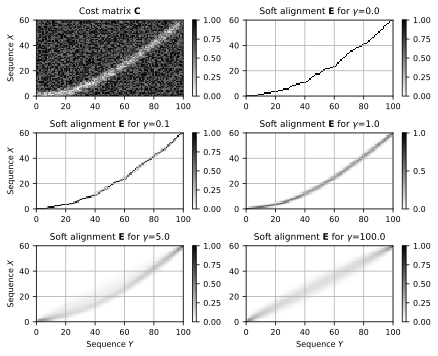

In [3]:
C = generate_cost_matrix(N=60, M=100, n_paths=1)

N, M = C.shape[1:]

gammas = [1e-10, 0.1, 1.0, 5.0, 100]

fig, ax = plt.subplots(3, 2, figsize=(6.2, 5))
im0 = ax[0, 0].imshow(
    C[0].detach().numpy(),
    cmap="gray_r",
    interpolation="None",
    origin="lower",
    aspect="auto",
    extent=[0, M, 0, N],
)
fig.colorbar(im0, ax=ax[0, 0])
ax[0, 0].set_title(r"Cost matrix $\mathbf{C}$")

for i, gamma in enumerate(gammas):
    sdtw_loss = SDTW(gamma=gamma, store_debug=True)
    loss = sdtw_loss(C=C)
    loss.backward()

    E = sdtw_loss.core.E_matrix[0].detach().numpy()

    im = ax.flatten()[i + 1].imshow(
        E,
        cmap="gray_r",
        interpolation="None",
        origin="lower",
        aspect="auto",
        extent=[0, M, 0, N],
    )
    fig.colorbar(im, ax=ax.flatten()[i + 1])
    ax.flatten()[i + 1].grid()
    ax.flatten()[i + 1].set_title(
        r"Soft alignment $\mathbf{E}$ for $\gamma$=%.1f" % gamma
    )

for ax_ in ax.flatten()[::2]:
    ax_.set_ylabel(r"Sequence $X$")

for ax_ in ax.flatten()[-2:]:
    ax_.set_xlabel(r"Sequence $Y$")

fig.tight_layout()

<a id="two_paths"></a>

## Two Dominant Paths

We add a second low-cost corridor. Compare the resulting soft alignments with the previous example. Does the gradient select one corridor, or distribute weight across both? Inspect how this depends on $\gamma$.

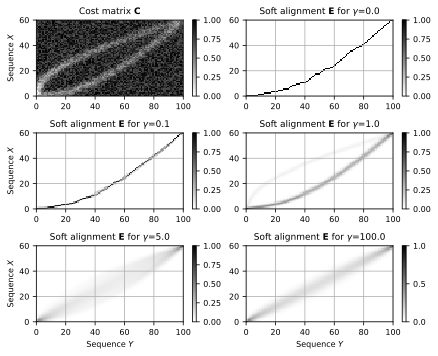

In [4]:
C = generate_cost_matrix(N=60, M=100, n_paths=2)

N, M = C.shape[1:]

gammas = [1e-10, 0.1, 1.0, 5.0, 100]

fig, ax = plt.subplots(3, 2, figsize=(6.2, 5))
im0 = ax[0, 0].imshow(
    C[0].detach().numpy(),
    cmap="gray_r",
    interpolation="None",
    origin="lower",
    aspect="auto",
    extent=[0, M, 0, N],
)
fig.colorbar(im0, ax=ax[0, 0])
ax[0, 0].set_title(r"Cost matrix $\mathbf{C}$")

for i, gamma in enumerate(gammas):
    sdtw_loss = SDTW(gamma=gamma, store_debug=True)
    loss = sdtw_loss(C=C)
    loss.backward()

    E = sdtw_loss.core.E_matrix[0].detach().numpy()

    im = ax.flatten()[i + 1].imshow(
        E,
        cmap="gray_r",
        interpolation="None",
        origin="lower",
        aspect="auto",
        extent=[0, M, 0, N],
    )
    fig.colorbar(im, ax=ax.flatten()[i + 1])
    ax.flatten()[i + 1].grid()
    ax.flatten()[i + 1].set_title(
        r"Soft alignment $\mathbf{E}$ for $\gamma$=%.1f" % gamma
    )

for ax_ in ax.flatten()[::2]:
    ax_.set_ylabel(r"Sequence $X$")

for ax_ in ax.flatten()[-2:]:
    ax_.set_xlabel(r"Sequence $Y$")

fig.tight_layout()

<a id="expected_paths"></a>

<div style="
  background-color: #C8E6C9A0;
  border: 1px solid #81C784A0;
  padding: 10px 20px;
  margin: 10px 0;
  color: #1B5E20;
">

<h2 style="color:#1B5E20; margin-top:0;">Background: Expected Alignments</h2>

For unit step weights, each path has cost
$c_\mathbf{A}(\mathbf{C})=\langle \mathbf{C},\mathbf{A}\rangle$ and probability
$p^\gamma(\mathbf{A}\mid \mathbf{C})=e^{-c_\mathbf{A}/\gamma}/\sum_{\mathbf{A}'}e^{-c_{\mathbf{A}'}/\gamma}$.

The gradient is $\mathbf{E}=\sum_\mathbf{A} p^\gamma(\mathbf{A}\mid \mathbf{C})\mathbf{A}$. It describes expected
cell visits, not a single path and not a row-normalized correspondence
matrix. Several cells in one row can be visited along a path.

As gamma approaches zero, mass concentrates on minimum-cost paths;
ties can retain multiple paths. At large gamma the distribution over
paths approaches uniformity, but cell values need not be uniform because
different cells belong to different numbers of valid paths.

</div>

<div style="
  background-color: #FFE0B2A0;
  border: 1px solid #FFC671A0;
  padding-top: 10px;
  padding-bottom: 10px;
  padding-left: 20px;
  padding-right: 20px;
  margin-top: 10px;
  margin-bottom: 10px;
">

<h2 style="color:#E65100; margin-top:0;">Attention: Keep Path Conventions Consistent</h2>

<p style="color:#E65100;">
    Global and recursive computations must use the same start and end cells,
    allowed steps, step weights, temperature, and normalization. Exhaustive
    enumeration is only practical for tiny matrices because path counts grow
    rapidly. The 3 × 4 example below has 25 valid paths.
    </p>

</div>

<a id="exercise_costs"></a>

<div style="
  background-color: #B2EBF290;
  border: 1px solid #4DD0E190;
  padding-top: 10px;
  padding-bottom: 10px;
  padding-left: 20px;
  padding-right: 20px;
  margin-top: 10px;
  margin-bottom: 10px;
">

<strong style="color:#006064; display:block; break-after:avoid; page-break-after:avoid;">Exercise 1: Designing a Cost Matrix</strong>

<ol style="color:#006064;">
<li>Create your own low-cost corridor and plot soft alignments for several temperatures.</li>
<li>Add a competing corridor and explain how the gradient changes.</li>
</ol>

</div>

### Solution: Designing a Cost Matrix

The following matrix has one diagonal corridor, or two bent corridors
joining the same endpoints. Small gamma favors cheaper paths within the
corridors; increasing gamma spreads mass to less favorable paths. With
equally costly competing paths, even a sharp alignment can retain both.

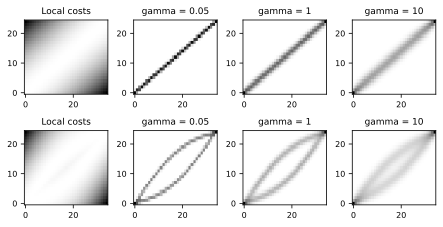

In [5]:
N_demo, M_demo = 25, 35
rows = np.arange(N_demo)[:, None]
phase = np.linspace(0, 1, M_demo)[None, :]
center = (N_demo - 1) * phase
bend = 5 * np.sin(np.pi * phase)
one_corridor = ((rows - center) / 3) ** 2
two_corridors = np.minimum(
    ((rows - center - bend) / 3) ** 2,
    ((rows - center + bend) / 3) ** 2,
)
fig, ax = plt.subplots(2, 4, figsize=(6.2, 3.2), layout="tight")
for r, costs in enumerate([one_corridor, two_corridors]):
    ax[r, 0].imshow(costs, origin="lower", aspect="auto", cmap="gray_r")
    ax[r, 0].set_title("Local costs")
    for j, gamma in enumerate([0.05, 1.0, 10.0], start=1):
        C_demo = torch.tensor(costs[None], requires_grad=True)
        aligner = SDTW(
            gamma=gamma,
            store_debug=True,
            step_sizes=[[1, 0], [1, 1], [0, 1]],
            global_step_weights=[1, 1, 1],
            normalization="none",
            dtype_float=torch.float64,
        )
        aligner(C=C_demo).sum().backward()
        ax[r, j].imshow(
            C_demo.grad[0].numpy(),
            origin="lower",
            aspect="auto",
            cmap="gray_r",
        )
        ax[r, j].set_title(f"gamma = {gamma:g}")
plt.show()

<a id="exercise_global"></a>

<div style="
  background-color: #B2EBF290;
  border: 1px solid #4DD0E190;
  padding-top: 10px;
  padding-bottom: 10px;
  padding-left: 20px;
  padding-right: 20px;
  margin-top: 10px;
  margin-bottom: 10px;
">

<strong style="color:#006064; display:block; break-after:avoid; page-break-after:avoid;">Exercise 2: Global Formulation and Dynamic Programming</strong>

<ol style="color:#006064;">
<li>Initialize a random 3 × 4 cost matrix, count all valid paths, and generate their alignment matrices for steps (1,0), (1,1), and (0,1).</li>
<li>Compute all path costs, the global SDTW value, and the expected alignment.</li>
<li>Compare with dDTW using the same gamma, unit weights, and no normalization.</li>
</ol>

</div>

### Solution: Global Formulation and Dynamic Programming

Recursively visit every legal successor from $(0,0)$ to $(N-1,M-1)$,
saving one binary matrix per path. There are 25 paths for a 3 × 4 matrix.
Stack their costs into $c$ and compute
$s=-\gamma\operatorname{logsumexp}(-c/\gamma)$ and
$E=\sum_A\operatorname{softmax}(-c/\gamma)_A A$.
The assertions below compare both the scalar value and its cost gradient.

In [6]:
def get_alignment_matrices(N, M):
    """Return binary DTW alignment matrices for lengths N and M.

    Valid DTW steps are (1, 0), (0, 1), and (1, 1).
    """
    if N < 1 or M < 1:
        raise ValueError("N and M must be positive integers.")

    # initialize a list to store the alignment matrices and a matrix to track
    # the current path

    matrices = []
    matrix = np.zeros((N, M), dtype=np.int8)

    # recursively visit all paths
    def step(i, j):
        matrix[i, j] = 1

        # we have reached the end -> store that alignment matrix
        if i == N - 1 and j == M - 1:
            matrices.append(matrix.copy())

        # we have not reached the end -> continue exploring the next steps
        else:
            if i + 1 < N:
                step(i + 1, j)
            if j + 1 < M:
                step(i, j + 1)
            if i + 1 < N and j + 1 < M:
                step(i + 1, j + 1)

        # erase the current step before returning to the previous step
        matrix[i, j] = 0

    # start exploring at the start cell
    step(0, 0)
    return matrices

In [7]:
N = 3
M = 4
C = np.random.rand(N, M)

alignment_matrices = get_alignment_matrices(N=3, M=4)

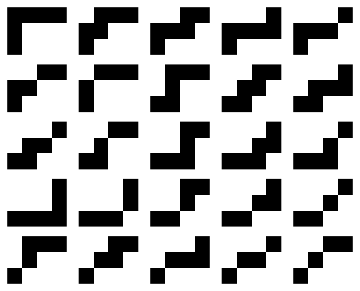

In [8]:
fig, ax = plt.subplots(5, 5, figsize=(6.2, 5))
for ax_, A in zip(ax.flatten(), alignment_matrices):
    im = ax_.imshow(
        A,
        cmap="gray_r",
        interpolation="None",
        origin="lower",
        aspect="auto",
        extent=[0, M, 0, N],
    )
    # ax_.grid()
    # ax_.set_title(r"Alignment matrix $\mathbf{A}$")
    ax_.set_axis_off()

In [9]:
alignment_costs = [np.sum(A * C) for A in alignment_matrices]

Valid paths: 25
Global / recursive SDTW: 0.7860439315203653 0.7860439315203656


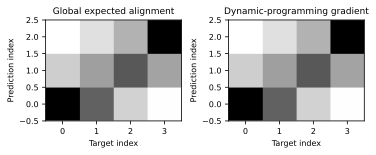

In [10]:
gamma = 0.7
paths = torch.tensor(np.stack(alignment_matrices), dtype=torch.float64)
costs = torch.tensor(alignment_costs, dtype=torch.float64)
global_value = -gamma * torch.logsumexp(-costs / gamma, dim=0)
path_probabilities = torch.softmax(-costs / gamma, dim=0)
global_alignment = torch.einsum("p,pnm->nm", path_probabilities, paths)
assert len(alignment_matrices) == 25

C_dp = torch.tensor(C[None], dtype=torch.float64, requires_grad=True)
dp = SDTW(
    gamma=gamma,
    step_sizes=[[1, 0], [1, 1], [0, 1]],
    global_step_weights=[1, 1, 1],
    normalization="none",
    dtype_float=torch.float64,
    store_debug=True,
)
dp_value = dp(C=C_dp).sum()
dp_value.backward()
torch.testing.assert_close(dp_value, global_value)
torch.testing.assert_close(C_dp.grad[0], global_alignment)
print("Valid paths:", len(alignment_matrices))
print("Global / recursive SDTW:", global_value.item(), dp_value.item())

fig, ax = plt.subplots(1, 2, figsize=(5.2, 2.2), layout="tight")
for a, values, title in zip(
    ax,
    [global_alignment.numpy(), C_dp.grad[0].numpy()],
    ["Global expected alignment", "Dynamic-programming gradient"],
):
    a.imshow(values, origin="lower", aspect="auto", cmap="gray_r")
    a.set(title=title, xlabel="Target index", ylabel="Prediction index")
plt.show()